# Lab 1b: perceptron and SVM on the Iris data

The Iris data set (R. A. Fisher, 1936) contains 150 flowers of three species — *setosa*, *versicolor*, *virginica* — with four measurements in cm: sepal length, sepal width, petal length, petal width.

Cells marked **TODO** are for you to complete; check cells print `OK` when your answer is correct.

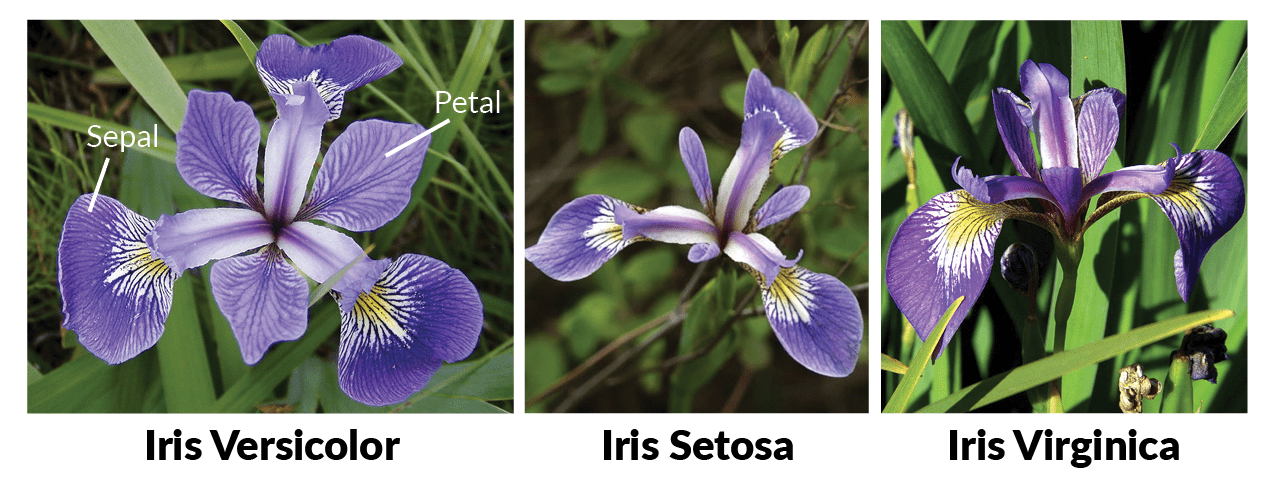

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

plt.rc("axes", labelsize=13)

## 1. Data: is the flower *setosa*?

**TODO 1.** `iris.data` is a table 150 × 4. Select the two **petal** columns (columns 2 and 3) into `X`, and create `y` equal to 1 for setosa (`iris.target == 0`) and 0 otherwise. *Hint:* `iris.data[:, 2:4]`; `(condition).astype(int)`.

In [5]:
iris = load_iris()
print(iris.feature_names)
print(iris.target_names)

# TODO: select petal length and width; labels 1 = setosa, 0 = other
X = iris.data[:, 2:4]
y = (iris.target == 0).astype(int)
print(X.shape, np.bincount(y))

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']
(150, 2) [100  50]


In [6]:
assert X.shape == (150, 2) and np.isclose(X[0, 0], 1.4) and y.sum() == 50 and y[0] == 1
print('OK, correct!')

OK, correct!


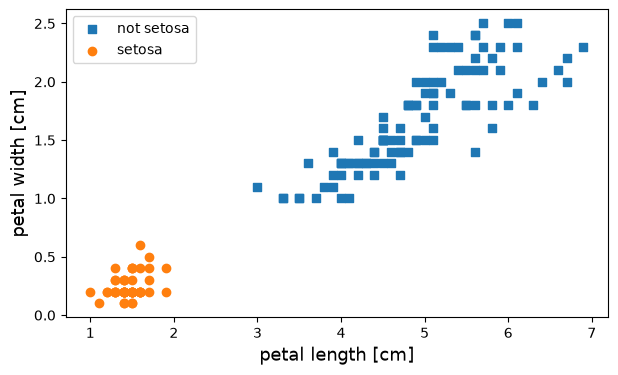

In [7]:
plt.figure(figsize=(7, 4))
plt.scatter(*X[y == 0].T, marker="s", label="not setosa")
plt.scatter(*X[y == 1].T, marker="o", label="setosa")
plt.xlabel("petal length [cm]"); plt.ylabel("petal width [cm]")
plt.legend(); plt.show()

## 2. Perceptron in scikit-learn

In [8]:
per_clf = Perceptron(max_iter=1000, tol=1e-3, random_state=42)
per_clf.fit(X, y)

print("weights w =", per_clf.coef_[0], " bias b =", per_clf.intercept_[0])
print("epochs run:", per_clf.n_iter_)
print("training accuracy:", per_clf.score(X, y))

weights w = [-1.4 -2.2]  bias b = 4.0
epochs run: 7
training accuracy: 1.0


**TODO 2.** Use `per_clf.predict` to classify a new flower with petal length 2 cm and petal width 0.5 cm. *Hint:* `predict` expects a table — a list of rows: `[[length, width]]`.

In [9]:
# TODO: predict the class of a flower with petal length 2.0 and width 0.5
new_pred = per_clf.predict([[2.0, 0.5]])
print(new_pred)          # 1 -> setosa

[1]


In [10]:
assert list(new_pred) == [1]
print('OK, correct!')

OK, correct!


## 3. Decision boundary

The boundary is the line $w_1x_1 + w_2x_2 + b = 0$, i.e. $x_2 = -\frac{w_1}{w_2}x_1 - \frac{b}{w_2}$. The helper function below draws it.

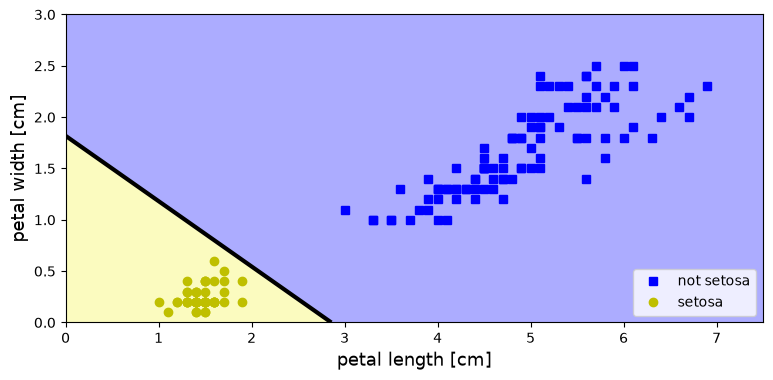

In [11]:
def plot_decision(clf, X, y, labels, axes, show_margin=False):
    x0, x1 = np.meshgrid(np.linspace(axes[0], axes[1], 500), np.linspace(axes[2], axes[3], 300))
    grid = np.c_[x0.ravel(), x1.ravel()]
    zz = clf.decision_function(grid).reshape(x0.shape)       # z = w1*x1 + w2*x2 + b

    plt.figure(figsize=(9, 4))
    plt.contourf(x0, x1, zz >= 0, cmap=ListedColormap(["#9898ff", "#fafab0"]), alpha=0.8)
    plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label=labels[0])
    plt.plot(X[y == 1, 0], X[y == 1, 1], "yo", label=labels[1])
    plt.contour(x0, x1, zz, levels=[0], colors="k", linewidths=3)
    if show_margin:                                          # SVM: margin and support vectors
        plt.contour(x0, x1, zz, levels=[-1, 1], colors="k", linestyles="--")
        sv = clf.support_vectors_
        plt.scatter(sv[:, 0], sv[:, 1], s=180, facecolors="none", edgecolors="r", linewidths=1.5,
                    label="support vectors")
    plt.xlabel("petal length [cm]"); plt.ylabel("petal width [cm]")
    plt.legend(loc="lower right"); plt.axis(axes); plt.show()

plot_decision(per_clf, X, y, ["not setosa", "setosa"], axes=[0, 7.5, 0, 3])

## 4. Our own implementation (from Lab 1a)

**TODO 3.** Compute the training accuracy of our perceptron: the fraction of examples where the answer equals the correct label. *Hint:* `(a == b)` gives True/False; `.mean()` of it is the fraction of True.

In [12]:
def predict(X, w, b):
    return (X @ w + b >= 0).astype(int)

def fit_perceptron(X, d, eta=1.0, max_epochs=100):
    w, b, history = np.zeros(X.shape[1]), 0.0, []
    for _ in range(max_epochs):
        mistakes = 0
        for x_j, d_j in zip(X, d):
            e = d_j - predict(x_j, w, b)
            w, b = w + eta * e * x_j, b + eta * e
            mistakes += abs(e)
        history.append(int(mistakes))
        if mistakes == 0:
            break
    return w, b, history

w, b, hist = fit_perceptron(X, y)
print("w =", w, " b =", b, "  mistakes per epoch:", hist)

# TODO: training accuracy of our perceptron
acc = (predict(X, w, b) == y).mean()
print("training accuracy:", acc)

w = [-0.6 -0.8]  b = 2.0   mistakes per epoch: [1, 3, 0]
training accuracy: 1.0


In [13]:
assert np.isclose(acc, 1.0)
print('OK, correct!')

OK, correct!


The weights differ from scikit-learn's (different order of examples, stopping rule), but both lines separate the two classes without mistakes.

## 5. A harder pair: *versicolor* vs *virginica*

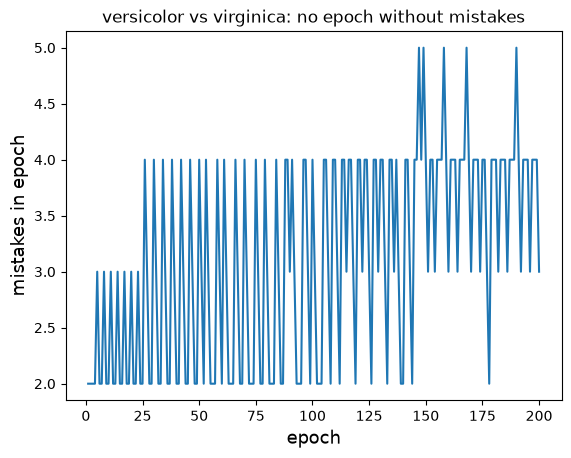

In [14]:
mask = iris.target > 0                          # drop setosa
X2 = iris.data[mask][:, 2:4]
y2 = (iris.target[mask] == 2).astype(int)       # 1 = virginica, 0 = versicolor

w, b, hist = fit_perceptron(X2, y2, max_epochs=200)
plt.plot(range(1, len(hist) + 1), hist)
plt.xlabel("epoch"); plt.ylabel("mistakes in epoch")
plt.title("versicolor vs virginica: no epoch without mistakes")
plt.show()

The classes overlap, so no line is perfect and the perceptron keeps changing its weights. We therefore measure accuracy on **test data** not used for training (30% of the flowers).

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X2, y2, test_size=0.3, stratify=y2, random_state=0)
print(len(X_train), "training flowers,", len(X_test), "test flowers")

accs = []
for seed in range(10):                      # seed = random order of the examples
    clf = Perceptron(max_iter=1000, tol=1e-3, random_state=seed).fit(X_train, y_train)
    accs.append(clf.score(X_test, y_test))
print("perceptron, test accuracy for 10 seeds:", np.round(accs, 2))

70 training flowers, 30 test flowers
perceptron, test accuracy for 10 seeds: [0.5  0.97 0.87 0.9  0.63 1.   0.57 0.87 0.93 0.6 ]


The result depends strongly on the (random) order of the examples.

## 6. Support vector machine (SVM)

A linear SVM also draws a straight line, but chooses the one with the **widest margin**. When the classes overlap,
the parameter `C` decides how much violating the margin is penalised (small `C`: wide margin, many violations allowed;
large `C`: narrow margin).

**TODO 4.** Create a linear SVM with `C=1.0`, train it on the training data and compute its test accuracy.
*Hint:* `SVC(kernel="linear", C=1.0)`, then `.fit(...)` and `.score(...)` as for the perceptron.

In [16]:
# TODO: linear SVM with C=1.0: create, fit on (X_train, y_train), score on (X_test, y_test)
svm = SVC(kernel="linear", C=1.0)
svm.fit(X_train, y_train)
svm_acc = svm.score(X_test, y_test)
print("SVM test accuracy:", round(svm_acc, 3))
print("number of support vectors:", len(svm.support_vectors_))

SVM test accuracy: 1.0
number of support vectors: 22


In [17]:
assert svm.kernel == "linear" and svm_acc >= 0.9
print('OK, correct!')

OK, correct!


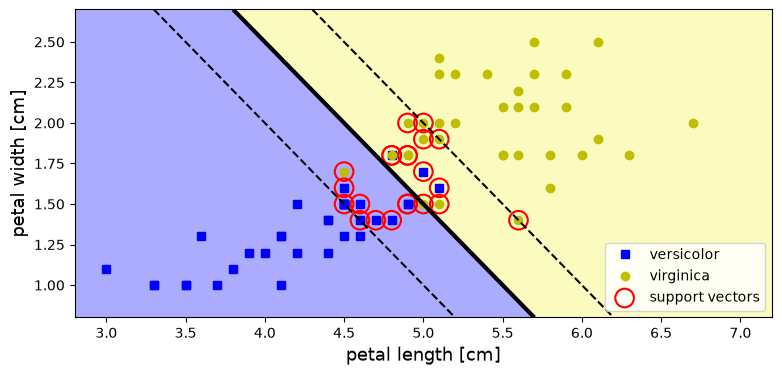

In [18]:
plot_decision(svm, X_train, y_train, ["versicolor", "virginica"], axes=[2.8, 7.2, 0.8, 2.7], show_margin=True)

SVM training does not depend on a random order of the data: running it again gives the same line.

**TODO 5.** Train linear SVMs for `C` in `[0.01, 0.1, 1, 10, 100]` and print, for each `C`, the training accuracy, the test accuracy and the number of support vectors.

In [19]:
for C in [0.01, 0.1, 1, 10, 100]:
    # TODO: train a linear SVM with this C and print the three numbers
    clf = SVC(kernel="linear", C=C)
    clf.fit(X_train, y_train)
    train_acc = clf.score(X_train, y_train)
    test_acc = clf.score(X_test, y_test)
    n_support = len(clf.support_vectors_)
    print(f"C={C:<6} train accuracy={train_acc:.3f}, test accuracy={test_acc:.3f}, support vectors={n_support}")

C=0.01   train accuracy=0.914, test accuracy=1.000, support vectors=70
C=0.1    train accuracy=0.929, test accuracy=0.967, support vectors=42
C=1      train accuracy=0.943, test accuracy=1.000, support vectors=22
C=10     train accuracy=0.929, test accuracy=1.000, support vectors=14
C=100    train accuracy=0.929, test accuracy=1.000, support vectors=12


Note: the test set has only 30 flowers, so one flower changes the accuracy by 0.033. Small differences between models here are not meaningful.

## Homework (separate tasks)

1. Plot the SVM boundary (`plot_decision(..., show_margin=True)`) for `C=0.01` and `C=100`. How do the margin and the number of support vectors change?
2. Use all four features (`iris.data[mask]`) for versicolor vs virginica. Compare the perceptron (10 seeds) and the linear SVM on the test set.
3. Try `SVC(kernel="rbf")`. Does a curved boundary help on this data?

#### Zadanie 1

Wniosek: przy małym C model mocniej toleruje błędy i zwykle wybiera szerszy margines. Przy dużym C silniej karze błędną klasyfikację, więc margines zwykle się zwęża. Liczba wektorów podpierających zależy od danych i może się zmieniać

C=0.01: liczba support vectors = 70


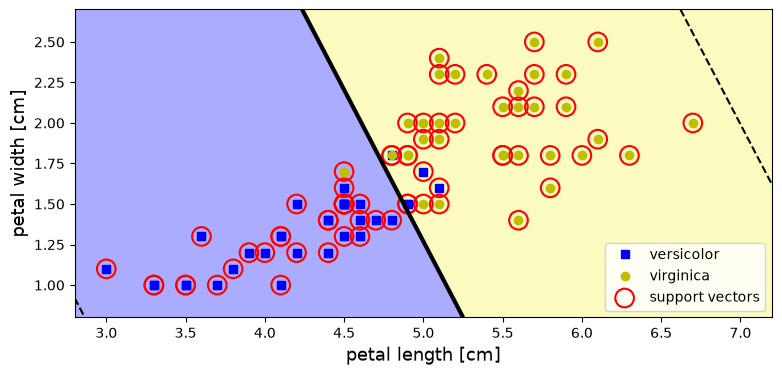

C=100: liczba support vectors = 12


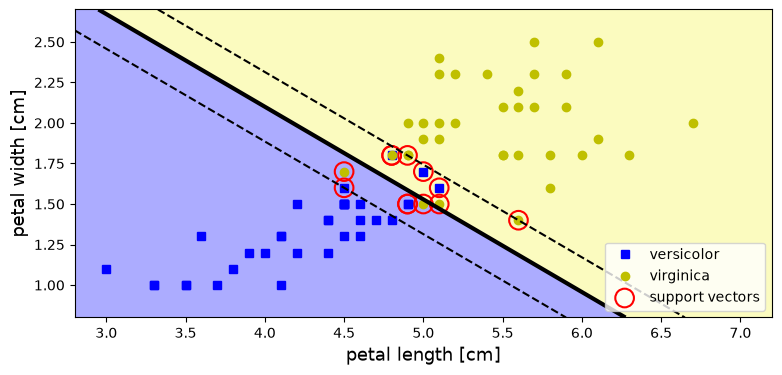

In [20]:
for C in [0.01, 100]:
    svm_C = SVC(kernel="linear", C=C)
    svm_C.fit(X_train, y_train)
    print(f"C={C}: liczba support vectors = {len(svm_C.support_vectors_)}")
    plot_decision(svm_C, X_train, y_train, ["versicolor", "virginica"],
                  axes=[2.8, 7.2, 0.8, 2.7], show_margin=True)

#### Zadanie 2

Wniosek: Liniowy SVM osiągnął dokładność 100% na zbiorze testowym, natomiast perceptron uzyskał średnią dokładność 84,3% w 10 uruchomieniach. Wyniki perceptronu były zmienne, a liniowy SVM uzyskał lepszy wynik w tym eksperymencie. Oznacza to, że dla zastosowanego podziału danych SVM klasyfikował próbki skuteczniej niż perceptron.

In [21]:
X4 = iris.data[mask]
y4 = y2
X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4, test_size=0.3, stratify=y4, random_state=0
)

perceptron_accs_4 = []
for seed in range(10):
    clf = Perceptron(max_iter=1000, tol=1e-3, random_state=seed)
    clf.fit(X4_train, y4_train)
    perceptron_accs_4.append(clf.score(X4_test, y4_test))
    
svm4 = SVC(kernel="linear", C=1.0)
svm4.fit(X4_train, y4_train)
svm4_acc = svm4.score(X4_test, y4_test)

print("Perceptron - test accuracy dla 10 seeds:", np.round(perceptron_accs_4, 3))
print("Perceptron - średnia dokładność:", round(float(np.mean(perceptron_accs_4)), 3))
print("Linear SVM - test accuracy:", round(svm4_acc, 3))

Perceptron - test accuracy dla 10 seeds: [0.9   0.967 1.    0.9   1.    0.5   1.    0.9   0.767 0.5  ]
Perceptron - średnia dokładność: 0.843
Linear SVM - test accuracy: 1.0


#### Zadanie 3

Wniosek: Liniowy SVM uzyskał dokładność 94,3% na zbiorze treningowym i 100% na testowym. SVM z jądrem RBF osiągnął odpowiednio 91,4% i 96,7%. W tym eksperymencie liniowy SVM uzyskał lepszy wynik na zbiorze testowym. Oba modele dobrze klasyfikowały dane, jednak bardziej złożona granica decyzyjna RBF nie poprawiła skuteczności. Wyniki nie przesądzają o przewadze jednego modelu w każdym przypadku.

Zakrzywiona granica nie poprawiła wyników klasyfikacji. W tym przypadku prosta granica była dokładniejsza.

Linear SVM - train: 0.943 test: 1.0
RBF SVM - train: 0.914 test: 0.967


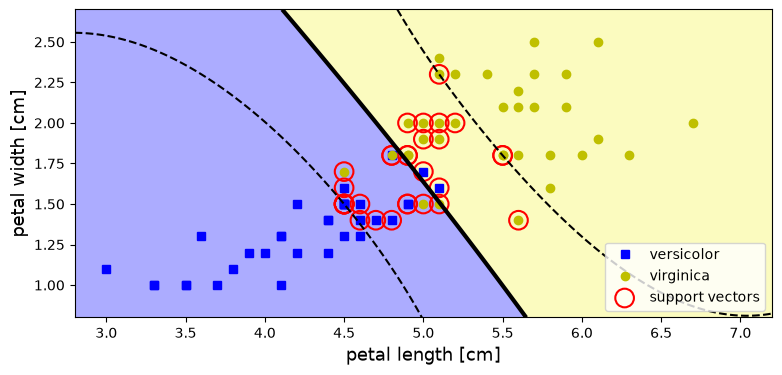

In [22]:
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale")
svm_rbf.fit(X_train, y_train)
rbf_train_acc = svm_rbf.score(X_train, y_train)
rbf_test_acc = svm_rbf.score(X_test, y_test)

print("Linear SVM - train:", round(svm.score(X_train, y_train), 3),
      "test:", round(svm.score(X_test, y_test), 3))
print("RBF SVM - train:", round(rbf_train_acc, 3),
      "test:", round(rbf_test_acc, 3))
plot_decision(svm_rbf, X_train, y_train, ["versicolor", "virginica"],
              axes=[2.8, 7.2, 0.8, 2.7], show_margin=True)